In [1]:
print("Air Quality Trend Predictor")
print("My first AI project!")
print("Let's detect air pollution patterns.")

Air Quality Trend Predictor
My first AI project!
Let's detect air pollution patterns.


In [4]:
%pip -q install ucimlrepo

In [5]:
import ucimlrepo

print("Installation successful!")

Installation successful!


In [6]:
from ucimlrepo import fetch_ucirepo

# Download the air quality dataset
dataset = fetch_ucirepo(id=501)

# Get the input data
X = dataset.data.features

# Get the pollution measurements
y = dataset.data.targets

print("Dataset downloaded successfully!")
print("Number of rows and columns:", X.shape)
print("\nColumn names:")
print(X.columns.tolist())

DatasetNotFoundError: "Beijing Multi-Site Air Quality" dataset (id=501) exists in the repository, but is not available for import. Please select a dataset from this list: https://archive.ics.uci.edu/datasets?skip=0&take=10&sort=desc&orderBy=NumHits&search=&Python=true

In [7]:

import pandas as pd
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality.zip"

print("Downloading the dataset...")

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    files = [f for f in z.namelist() if f.endswith(".csv")]
    print("CSV files found:", len(files))
    print("Example files:", files[:3])

HTTPError: 404 Client Error: Not Found for url: https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality.zip

In [8]:
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/501/PRSA2017_Data_20130301-20170228.zip"

print("Downloading dataset...")

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    files = [f for f in z.namelist() if f.endswith(".csv")]

    print("Download successful!")
    print("Number of CSV files:", len(files))
    print("First few files:", files[:3])

HTTPError: 404 Client Error: Not Found for url: https://archive.ics.uci.edu/static/public/501/PRSA2017_Data_20130301-20170228.zip

In [9]:
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00501/PRSA2017_Data_20130301-20170228.zip"

print("Connecting to the dataset server...")

response = requests.get(url, timeout=60)

print("HTTP status:", response.status_code)

response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    csv_files = [
        name for name in z.namelist()
        if name.endswith(".csv")
    ]

    print("\nDataset downloaded successfully!")
    print("Number of CSV files:", len(csv_files))
    print("\nFirst three files:")

    for name in csv_files[:3]:
        print(name)

Connecting to the dataset server...
HTTP status: 200

Dataset downloaded successfully!
Number of CSV files: 12

First three files:
PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_20130301-20170228/PRSA_Data_Dingling_20130301-20170228.csv


In [10]:
import pandas as pd
import zipfile
import io
import requests

# Download the dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00501/PRSA2017_Data_20130301-20170228.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

# Open the ZIP file
z = zipfile.ZipFile(io.BytesIO(response.content))

# Load one monitoring station
file_name = next(
    f for f in z.namelist()
    if f.endswith("PRSA_Data_Aotizhongxin_20130301-20170228.csv")
)

df = pd.read_csv(z.open(file_name))

# Display the data
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Number of rows and columns: (35064, 18)

First five rows:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin



Column names:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']


In [11]:
# Make a copy of our dataset
data = df.copy()

# Combine year, month, day and hour into a datetime column
data["datetime"] = pd.to_datetime(
    data[["year", "month", "day", "hour"]]
)

# Sort measurements chronologically
data = data.sort_values("datetime")

# Check missing values
print("Missing values before cleaning:")
print(data[["PM2.5", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]].isnull().sum())

# Fill missing measurements using time-based interpolation
data = data.set_index("datetime")

columns = ["PM2.5", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

data[columns] = data[columns].interpolate(method="time", limit_area="inside")

# Remove rows where PM2.5 is still missing
data = data.dropna(subset=["PM2.5"])

print("\nMissing values after cleaning:")
print(data[columns].isnull().sum())

print("\nRows remaining:", len(data))

Missing values before cleaning:
PM2.5    925
TEMP      20
PRES      20
DEWP      20
RAIN      20
WSPM      14
dtype: int64

Missing values after cleaning:
PM2.5    0
TEMP     0
PRES     0
DEWP     0
RAIN     0
WSPM     0
dtype: int64

Rows remaining: 35064


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# Make sure the data is in chronological order
data = data.sort_index()

# Create features from the previous hour
data["PM25_previous"] = data["PM2.5"].shift(1)

# Create the target: PM2.5 one hour into the future
data["PM25_future"] = data["PM2.5"].shift(-1)

# Features available for prediction
features = [
    "PM25_previous",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM"
]

# Remove rows with missing values in required columns
model_data = data[features + ["PM25_future"]].dropna()

# Keep the data in chronological order
split_index = int(len(model_data) * 0.8)

train = model_data.iloc[:split_index]
test = model_data.iloc[split_index:]

X_train = train[features]
y_train = train["PM25_future"]

X_test = test[features]
y_test = test["PM25_future"]

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Features:", features)

Training rows: 28049
Testing rows: 7013
Features: ['PM25_previous', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']


NameError: name 'predictions' is not defined

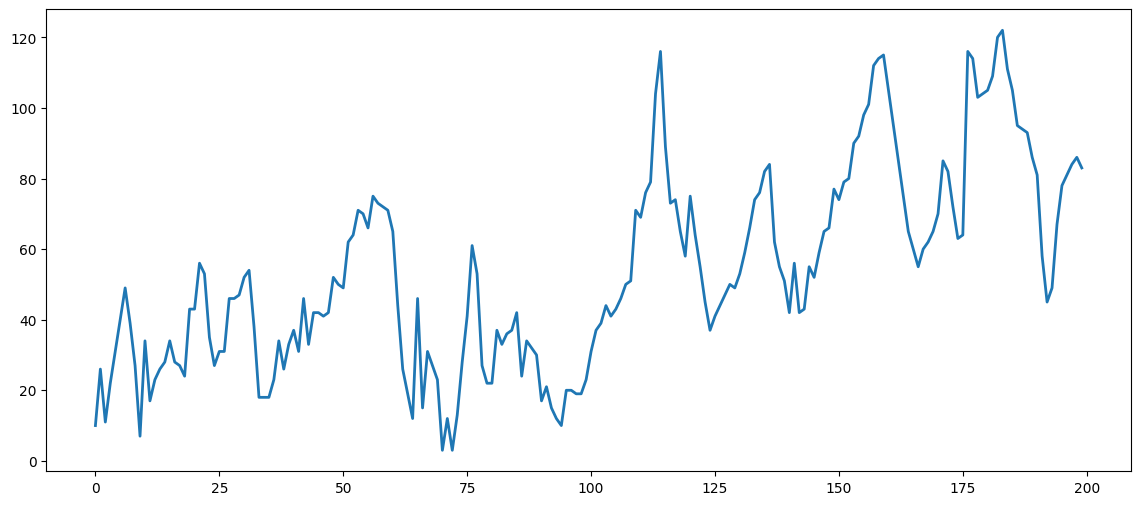

In [14]:
import matplotlib.pyplot as plt

# Compare actual and predicted values
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.iloc[:200].values,
    label="Actual PM2.5",
    linewidth=2
)

plt.plot(
    predictions[:200],
    label="Predicted PM2.5",
    linewidth=2
)

plt.title("Air Quality Predictor: Actual vs Predicted PM2.5")
plt.xlabel("Test observations")
plt.ylabel("PM2.5 concentration (µg/m³)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Model trained successfully!
Mean Absolute Error (MAE): 17.03


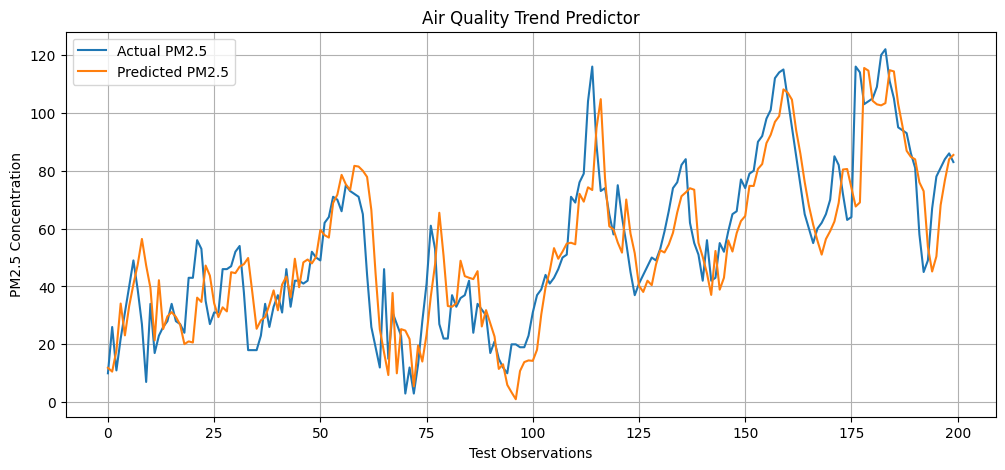

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# Train the model again
model = LinearRegression()
model.fit(X_train, y_train)

# Generate predictions
predictions = model.predict(X_test)

# Calculate the error
mae = mean_absolute_error(y_test, predictions)

print("Model trained successfully!")
print("Mean Absolute Error (MAE):", round(mae, 2))

# Plot actual vs predicted values
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.iloc[:200].values,
    label="Actual PM2.5"
)

plt.plot(
    predictions[:200],
    label="Predicted PM2.5"
)

plt.title("Air Quality Trend Predictor")
plt.xlabel("Test Observations")
plt.ylabel("PM2.5 Concentration")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
print("MODEL EVALUATION RESULTS")
print("------------------------")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Features used:", X_train.columns.tolist())
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))

print("\nActual vs Predicted PM2.5")
print("-------------------------")

for actual, predicted in zip(y_test.iloc[:10], predictions[:10]):
    print(f"Actual: {actual:.2f} | Predicted: {predicted:.2f}")

MODEL EVALUATION RESULTS
------------------------
Training samples: 28049
Testing samples: 7013
Features used: ['PM25_previous', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
MAE: 17.03

Actual vs Predicted PM2.5
-------------------------
Actual: 10.00 | Predicted: 11.89
Actual: 26.00 | Predicted: 10.57
Actual: 11.00 | Predicted: 17.88
Actual: 22.00 | Predicted: 34.10
Actual: 31.00 | Predicted: 23.10
Actual: 40.00 | Predicted: 33.22
Actual: 49.00 | Predicted: 40.74
Actual: 39.00 | Predicted: 47.48
Actual: 27.00 | Predicted: 56.42
Actual: 7.00 | Predicted: 47.26


CORRECTED BASELINE RESULTS
--------------------------
Training samples: 27127
Testing samples: 6782
Forecast horizon: 1 hour
Features: ['PM2.5', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
MAE: 10.48 µg/m³


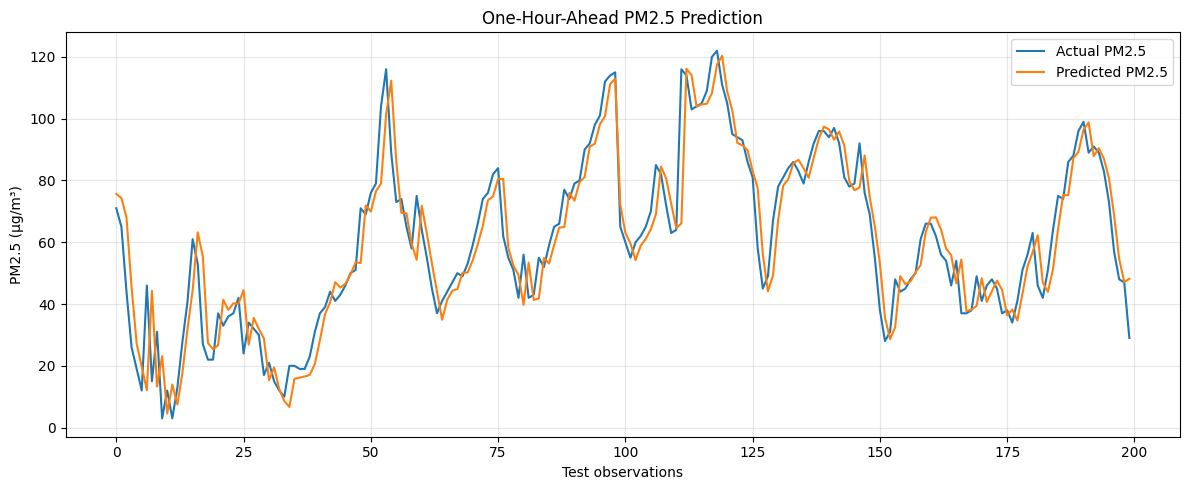

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Start again from the original, un-interpolated data
clean_data = df.copy()

# Create timestamps and sort chronologically
clean_data["datetime"] = pd.to_datetime(
    clean_data[["year", "month", "day", "hour"]]
)

clean_data = clean_data.sort_values("datetime")
clean_data = clean_data.set_index("datetime")

# Features available at the current hour
features = [
    "PM2.5",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM"
]

# Target: PM2.5 one hour later
clean_data["target"] = clean_data["PM2.5"].shift(-1)

# Identify the next observation's timestamp
next_time = pd.Series(
    clean_data.index,
    index=clean_data.index
).shift(-1)

# Keep only observations exactly one hour apart
hourly = clean_data[
    next_time - clean_data.index == pd.Timedelta(hours=1)
].copy()

# Remove rows with missing feature or target values
model_data = hourly[features + ["target"]].dropna()

# Split chronologically: first 80% for training, last 20% for testing
split = int(len(model_data) * 0.8)

train = model_data.iloc[:split]
test = model_data.iloc[split:]

X_train = train[features]
y_train = train["target"]

X_test = test[features]
y_test = test["target"]

# Train and evaluate the model
model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)

print("CORRECTED BASELINE RESULTS")
print("--------------------------")
print("Training samples:", len(train))
print("Testing samples:", len(test))
print("Forecast horizon: 1 hour")
print("Features:", features)
print(f"MAE: {mae:.2f} µg/m³")

# Plot the first 200 test predictions
plt.figure(figsize=(12, 5))
plt.plot(y_test.iloc[:200].values, label="Actual PM2.5")
plt.plot(predictions[:200], label="Predicted PM2.5")
plt.title("One-Hour-Ahead PM2.5 Prediction")
plt.xlabel("Test observations")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

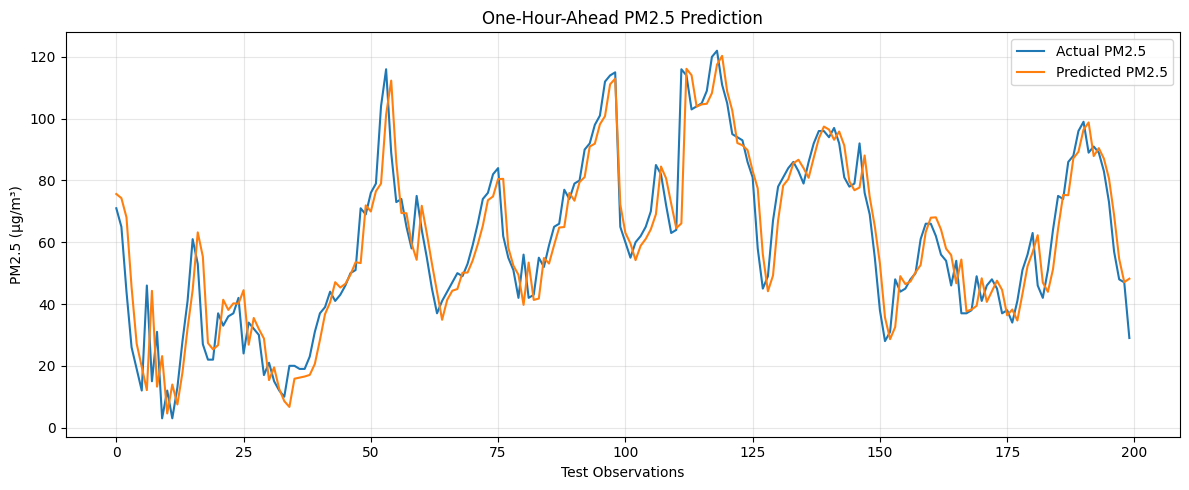

Graph saved successfully!
File: results/actual_vs_predicted.png


In [18]:
import os
import matplotlib.pyplot as plt

# Create a folder for project results
os.makedirs("results", exist_ok=True)

# Plot actual and predicted values
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.iloc[:200].values,
    label="Actual PM2.5"
)

plt.plot(
    predictions[:200],
    label="Predicted PM2.5"
)

plt.title("One-Hour-Ahead PM2.5 Prediction")
plt.xlabel("Test Observations")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the graph
plt.savefig("results/actual_vs_predicted.png", dpi=150)

plt.show()

print("Graph saved successfully!")
print("File: results/actual_vs_predicted.png")

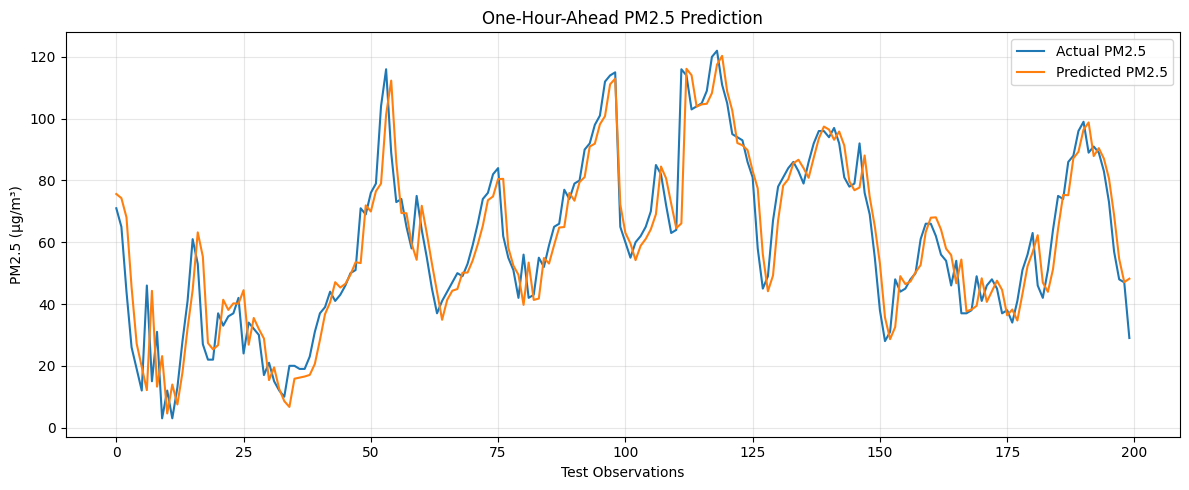

Graph saved successfully!
File: results/actual_vs_predicted.png


In [19]:
import os
import matplotlib.pyplot as plt

# Create a folder for project results
os.makedirs("results", exist_ok=True)

# Plot actual and predicted values
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.iloc[:200].values,
    label="Actual PM2.5"
)

plt.plot(
    predictions[:200],
    label="Predicted PM2.5"
)

plt.title("One-Hour-Ahead PM2.5 Prediction")
plt.xlabel("Test Observations")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the graph
plt.savefig("results/actual_vs_predicted.png", dpi=150)

plt.show()

print("Graph saved successfully!")
print("File: results/actual_vs_predicted.png")

In [20]:
from sklearn.metrics import mean_absolute_error

# Simple baseline: predict next-hour PM2.5
# using the current hour's PM2.5 measurement.
baseline_predictions = X_test["PM2.5"].to_numpy()

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

model_mae = mean_absolute_error(
    y_test,
    predictions
)

print("MODEL COMPARISON")
print("----------------")
print(f"Persistence baseline MAE: {baseline_mae:.2f}")
print(f"Linear Regression MAE:    {model_mae:.2f}")

if model_mae < baseline_mae:
    print("\nLinear Regression performed better on this test set.")
else:
    print("\nThe simple baseline performed as well as or better than Linear Regression.")

MODEL COMPARISON
----------------
Persistence baseline MAE: 10.36
Linear Regression MAE:    10.48

The simple baseline performed as well as or better than Linear Regression.
